# Intro

En pocas palabras, LoRA permite adaptar modelos preentrenados añadiendo matrices especiales a los pesos existentes y entrenando solo esos nuevos pesos.

Esto tiene un par de ventajas:

* Los pesos preentrenados anteriores se mantienen congelados, lo que evita que el modelo sufra catastrophic forgetting.
* Dichas matrices especiales tienen significativamente menos parámetros que el modelo original, lo que significa que los pesos entrenados de LoRA son fácilmente portables.

Para todos los detalles de ésta técnica de LLMs pueden consultar el paper original "[LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685)" en arxiv.

![Figura que muestra la idea detrás de LoRA](https://substackcdn.com/image/fetch/f_auto,q_auto:good,fl_progressive:steep/https%3A%2F%2Fsubstack-post-media.s3.amazonaws.com%2Fpublic%2Fimages%2Fee7f7d37-3c0a-4f4a-9244-f73287af6211_1456x612.jpeg)

Ésta notebook está basada en documentación de Hugging Face disponible en [git](https://github.com/huggingface/diffusers/tree/main/examples/dreambooth)

# Setup

Previo a comenzar a desarrollar el taller vamos a configurar lo que necesitamos:

* Debemos agregar a nuestro drive en alguna carpeta de su elección las fotos que vamos a utilizar para que la AI nos conozca. Lo genial de todo este proceso es que no necesitamos demasiadas, entre 3 y 5 es suficiente. Si lo deseamos podemos agregar algunas más, para mi ejemplo utilizo 7 pero diría que no necesitan más de 12. Busquen en particular que la mayoría sea con sus caras bien visibles y otras que sean de cuerpo entero para que también el modelo vea ejemplos de sus posturas.
* En el mismo directorio donde se encuentre la carpeta con nuestras fotos vamos a descargar ésta notebook y abrirla desde ahí.

Por ejemplo:

```
root
├── sample_fotos
│   ├── foto1.jpg
│   ├── foto2.jpg
│   └── ...
└── colab_notebook.ipynb
```

Una vez hecho lo anterior podemos correr las siguiente celda para montar nuestro Google Drive.

In [ ]:
# Vamos a importar dentro de Colab nuestro google drive.
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


**Nota**: Chequear el uso de GPU en settings de la notebook: `Runtime --> Change runtime type` y seleccionar otra cosa que no sea CPU (dependiendo de la suscripción a google colab tendran diferentes opciones).

Ahora simplemente vamos a definir una variable con la ruta a la carpeta elegida en Google Drive, para hacerlo más simple podemos hacer click secundario en nuestra carpeta (en la jerarquía) y elegir la opción "Copy path"

In [ ]:
# @markdown `IMAGES_PATH` es la ruta donde se encuentra nuestras
IMAGES_PATH = "/content/drive/MyDrive/GDG_Medellín/sample_fotos" # @param {type:"string"}

Vamos a chequear si estamos corriendo en GPU y bajo qué características.

In [ ]:
# Check type of GPU and VRAM available.
!nvidia-smi --query-gpu=name,memory.total,memory.free --format=csv,noheader

NVIDIA L4, 23034 MiB, 22698 MiB


Luego pasaremos a instalar los requerimientos y librerías necesarias para correr nuestra pequeña demo.

Empezamos por la librería [diffusers](https://huggingface.co/docs/diffusers/en/index), principal librería para el uso de modelos de difusión.

In [ ]:
!pip install -U -qq git+https://github.com/huggingface/diffusers.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Ahora instalamos un par de librerías auxiliares que nos pueden permitir a hacer más eficiente nuestro entrenamiento e inferencia, como el uso de [xformers](https://huggingface.co/docs/diffusers/en/optimization/xformers) and [bitsandbytes](https://huggingface.co/docs/bitsandbytes/main/en/index).

In [ ]:
!pip install -qq "accelerate>=0.16.0" torchvision "transformers>=4.25.1" ftfy tensorboard gradio xformers Jinja2
!pip install -qq "ipywidgets>=7,<8"
!pip install -qq bitsandbytes
!pip install -U --pre triton

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.6/50.6 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.7/56.7 MB 32.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.8/319.8 kB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 78.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.6/94.6 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.4/76.4 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.0/78.0 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.4/447.4 kB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.5/144.5 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 110.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.2/73.2 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/

También estaremos necesitando de [peft](https://github.com/huggingface/peft) para un finetuning más eficiente.

In [ ]:
!pip install peft

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.7/320.7 kB 21.5 MB/s eta 0:00:00


Necesitamos descargar ahora el script que nos va a permitir realizar nuestro finetuning

In [ ]:
!wget -q https://raw.githubusercontent.com/huggingface/diffusers/main/examples/dreambooth/train_dreambooth_lora.py

## Imports

In [ ]:
import PIL
from PIL import Image

from os.path import exists, join, isfile, realpath, isdir, basename, dirname
from os import listdir, makedirs

from diffusers import DiffusionPipeline, StableDiffusionPipeline
import torch

from accelerate.utils import write_basic_config

from tqdm.auto import tqdm

from IPython.display import clear_output
from IPython.display import Image as ipImage
from IPython.display import HTML
from IPython import display as ipythondisplay

import base64
import io

from datetime import datetime, timedelta

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

In [ ]:
write_basic_config()

PosixPath('/root/.cache/huggingface/accelerate/default_config.yaml')

## Utilidades

Algunas funciones para el manejo de archivos

In [ ]:
# Para listar directorios de una ruta
def get_dirs(dir_path: str, include_hidden_files: bool=False):
    dirs = [d for d in listdir(dir_path) if isdir(join(dir_path, d)) and (not d.startswith(".") or (d.startswith(".") and include_hidden_files))]
    return dirs

In [ ]:
# Para listar archivos de una ruta
def get_dir_files(dir_path: str):
    return [f for f in listdir(dir_path) if isfile(join(dir_path, f))]

In [ ]:
# Para mostrar imágenes en grilla de html.
def image_to_byte_array(image: Image, format="jpeg") -> bytes:
  bytes_array = io.BytesIO()
  image.save(bytes_array, format=format)
  bytes_array = bytes_array.getvalue()

  return bytes_array

Para crear una tabla HTML y mostrar las imágenes.

In [ ]:
# para mostrar imágenes
def show_img_comparison(images, resolution: int=512):
    begin_table =f"""
            <table>
                <thead> {[f"<th>{i}</th>" for i in range(len(images))]}
                <thead>
                <tbody>
                <tr>"""
    end_table = """
                    </tr>
                <tbody>
            </table>
        """

    mid_table = ""
    for img in images:
        encoded = base64.b64encode(image_to_byte_array(img))
        mid_table += f"""<td>
                        <img <source src="data:image/jpeg;base64,{encoded.decode('ascii')}" type="image/jpeg" height="{resolution}"/>
                        </img>
                        </td>
            """

    table = begin_table + mid_table + end_table
    ipythondisplay.display(HTML(data=table))

Antes de continuar veamos algo lo que hemos seleccionado entonces para el finetuning de nuestro modelo.

images


,,,

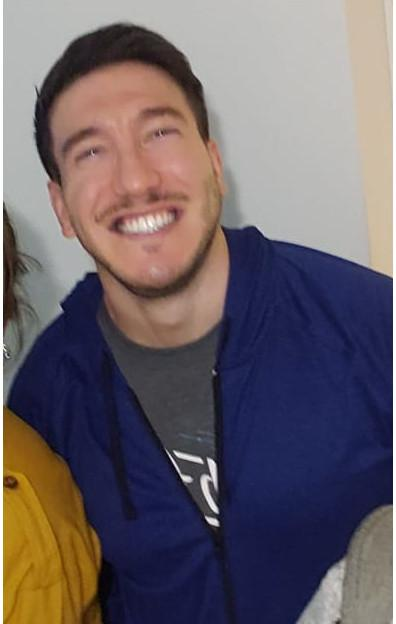
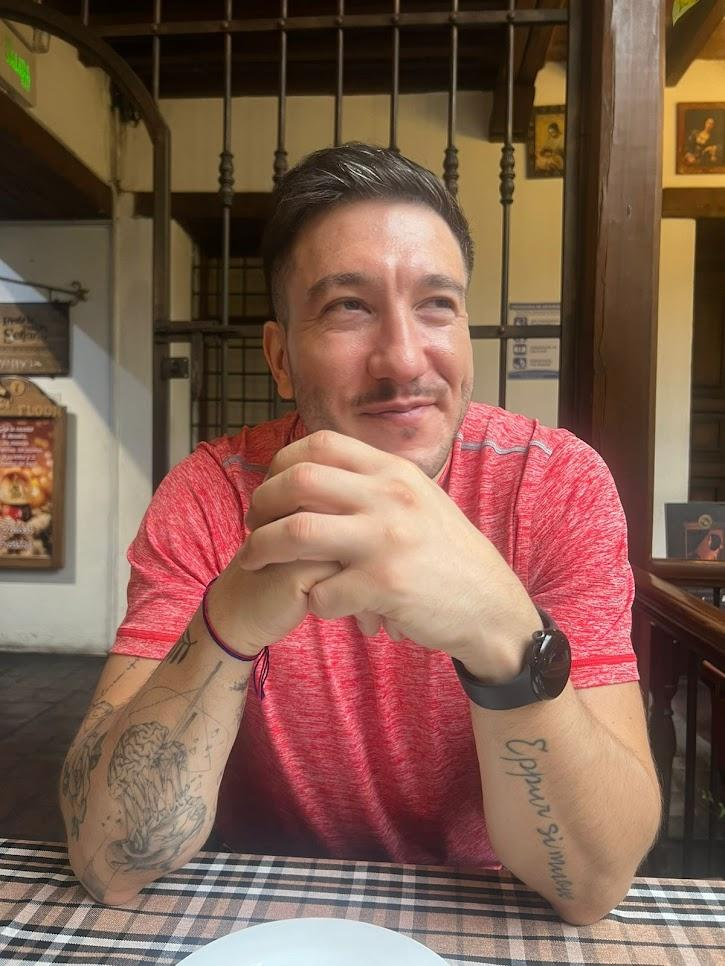
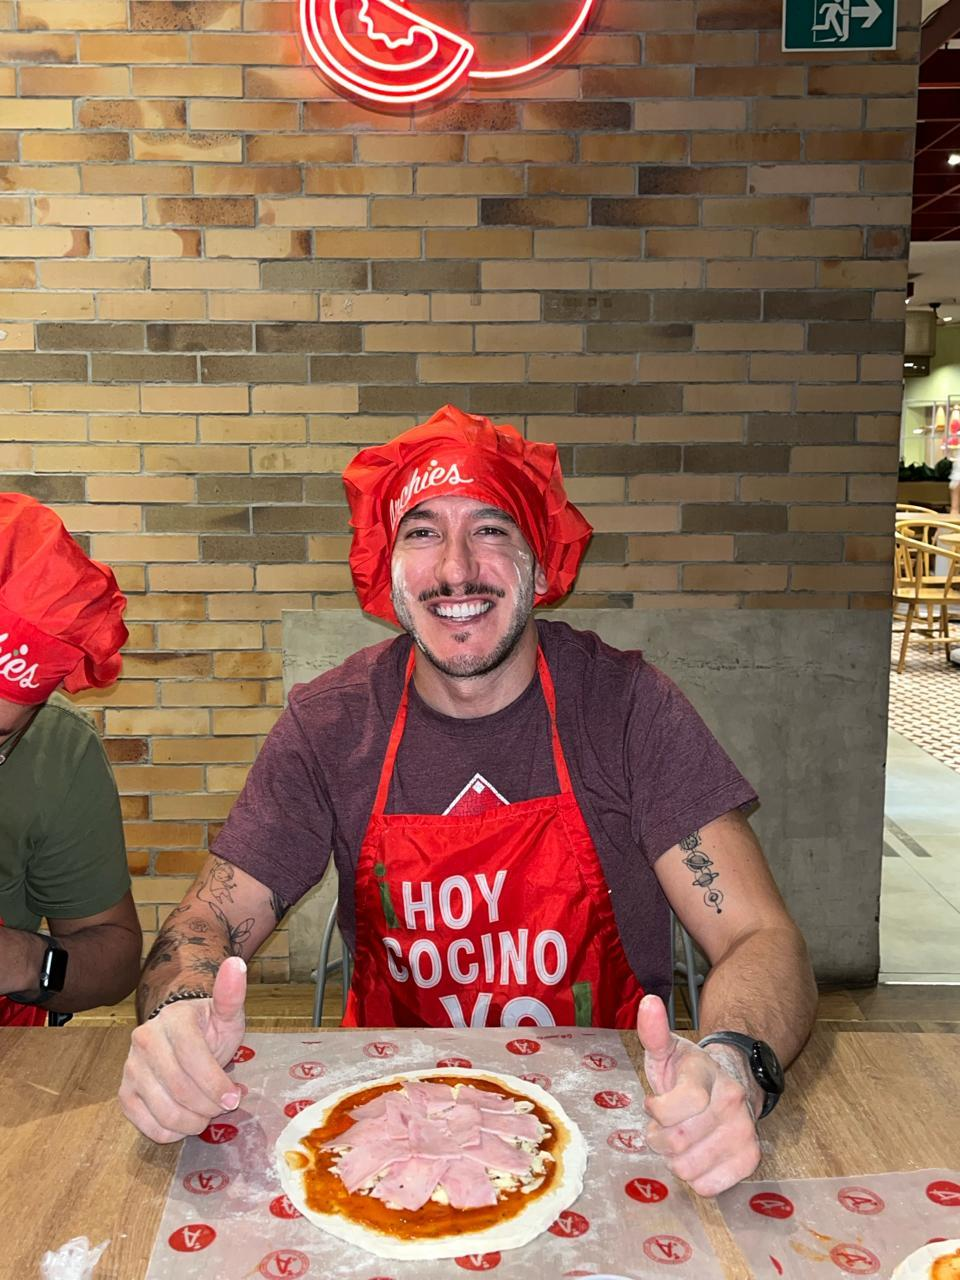
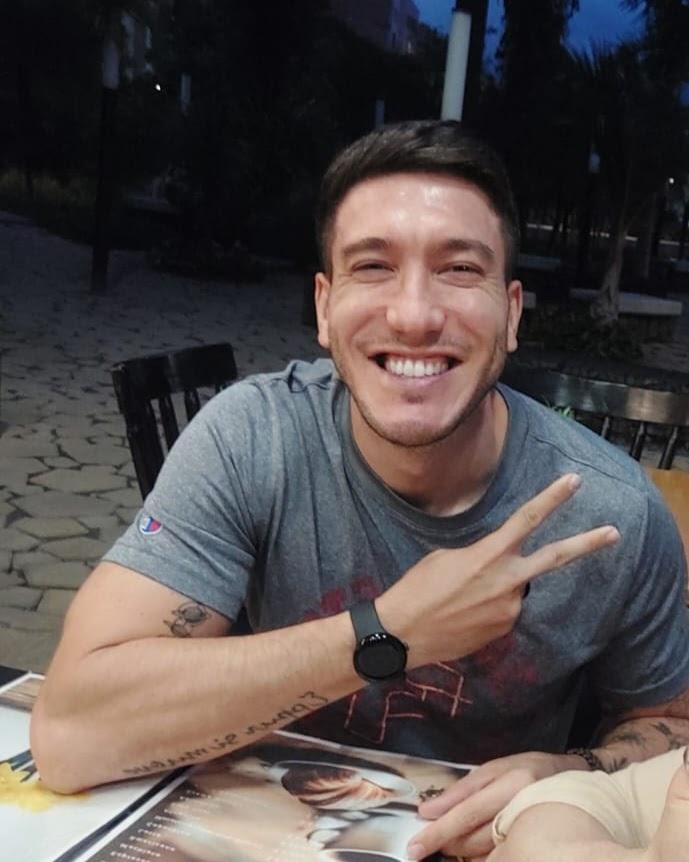

In [ ]:
images = get_dir_files(IMAGES_PATH)
images2show = []
for img in images[0:4]:
    image = Image.open(join(IMAGES_PATH, img))
    images2show.append(image)

print("images")
show_img_comparison(images2show, resolution=256)

# Dándonos a conocer

Con tan sólo unas pocas imágenes somos capaces de enseñarle un nuevo concepto al modelo mediante el uso de dreambooth.

## Sin priors

En éste ejemplo vamos a dejar por fuera el uso de priors, es decir los conceptos inherentes con los que el modelo ya cuenta. Recordar que el uso de los priors ayudan a mejorar el overfitting de las imágenes y el language drift del modelo.

Vamos ahora a crear nuestra carpeta para almacenar nuestro modelo.

Por defecto está para que se guarde en la VM que nos presta google, pero tener presente que ni bien termine el modelo debemos descargarla a nuestro disco para no perder el contenido, ya que luego de un tiempo la máquina se da de baja y se elimina todo su contenido. O la otra opción es guardarla directamente dentro de nuestro google drive en cualquier carpeta dentro de `/content/drive/MyDrive`.

In [ ]:
# @title Elegir dónde vamos a guardar nuestro modelo
# @markdown `OUTPUT_DIR` es la ruta donde guardaremos nuestro modelo
OUTPUT_DIR = "/content/drive/MyDrive/GDG_Medellín/finetuned_models/my_model_db_lora" # @param {type:"string"}

if not exists(OUTPUT_DIR):
    !mkdir -p "$OUTPUT_DIR"

Para agilizar un poco la corrida vamos a dejar por fuera el uso de priors. Recordar que los priors ayudan a mejorar el overfitting de las imágenes y el language drift del modelo.

In [ ]:
# @title Instrucciones para enseñarle un nuevo concepto
# @markdown `INSTANCE_PROMPT`: ¿Qué es lo que le estamos enseñando?.
INSTANCE_PROMPT = "a photo of a <mauri> man posing for the camera" # @param {type:"string"}
# @markdown `MAX_TRAINING_STEPS` es la cantidad máxima de pasos que vamos a utilizar para finetunear nuestra red. Se recomienda entre 200 y 300 pasos por cada imagen que se tenga para entrenar.
MAX_TRAINING_STEPS = 2100 # @param {type:"integer"}

In [ ]:
# @title Selección de nuestro modelo de difusión.
# @markdown `MODEL`: Establecemos nuestro modelo de preferencia, que en este caso será la versión 2.1, si quisieramos usar otras versiones hay que tener presente que la resolución podría necesitar ajustes.
MODEL = "stabilityai/stable-diffusion-2-1" # @param ["Jiali/stable-diffusion-1.5", "runwayml/stable-diffusion-v1-5", "stabilityai/stable-diffusion-2-1"]

Nota: StabilityAI solicitó la baja de runwayml/stable-diffusion-v1-5.

### Training

Ya tenemos todo listo, ahora corramos nuestro script.

En orden de poder correr nuestro modelo en las máquinas que google nos ofrece vamos a utilizar un par de parámetros adicionales en nuestro script:

* `--gradient_checkpointing`: helps to reduce the memory requirements during the backpropagation phase of training by trading computation for memory.
* `--use_8bit_adam`: to use 8-bit optimizer, allowing the finetune of large models that do not fit into memory otherwise.
* `--enable_xformers_memory_efficient_attention`: optimizes the memory and computational efficiency.
* `--set_grads_to_none`: para salvar incluso más memoria y tener algo más de performance.

Si tenemos una GPU lo suficientemente buena podemos prescindir de dichos parámetros. Incluso podríamos utilizar el parámetro `--train_text_encoder` para finetunear el encoder de texto junto con la UNet, ya que se ha observado experimentalmente que dicho finetuning ofrece resultados mucho mejores, especialmente en caras.

Bajo esta configuración de parámetros y con una GPU T4 nuestro script de finetuning debería demorar 2 horas aproximadamente en terminar.


**Nota**: Si tuvieramos más de una GPU (lucky you!) podríamos utilizar la librería [`accelerate`](https://github.com/huggingface/accelerate) para correr nuestro script.

In [ ]:
start_time = datetime.now()
print(f"Starting training at {str(start_time)}")

Starting training at 2024-10-24 17:37:37.583173


In [ ]:
!python3 train_dreambooth_lora.py \
  --pretrained_model_name_or_path="$MODEL" \
  --instance_data_dir="$IMAGES_PATH" \
  --output_dir="$OUTPUT_DIR" \
  --instance_prompt="$INSTANCE_PROMPT" \
  --resolution=768 \
  --train_batch_size=1 \
  --gradient_accumulation_steps=1 --gradient_checkpointing \
  --use_8bit_adam \
  --enable_xformers_memory_efficient_attention \
  --learning_rate=1e-4 \
  --lr_scheduler="constant" \
  --lr_warmup_steps=0 \
  --max_train_steps=$MAX_TRAINING_STEPS \
  --seed=1337

2024-10-24 17:37:42.365061: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-24 17:37:42.385806: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-24 17:37:42.392171: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-24 17:37:43.646953: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
10/24/2024 17:37:46 - INFO - __main__ - Distributed environment: NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: no

tokenizer/tokenizer_config.json: 100% 824/824 [00:00<00:00, 5.50MB/s]
tokeni

In [ ]:
end_time = datetime.now();
print(f"Ending training at {str(end_time)}")

elapsed_time = end_time - start_time

sec = elapsed_time.total_seconds() % (24 * 3600)
hour = sec // 3600
sec %= 3600
min = sec // 60
sec %= 60
print(f">>>>> Total elapsed time: {round(hour)}:{round(min)}:{sec}. <<<<<")

Ending training at 2024-10-24 19:14:05.528876
>>>>> Total elapsed time: 1:36:27.94570300000032. <<<<<


### Inference

Ahora vamos a ver qué tan bien nos conoció la AI. Pasaremos a cargar el modelo que usamos durante el finetuning utilizando una [pipeline](https://huggingface.co/docs/diffusers/en/api/pipelines/overview).

Las pipelines proporcionan una manera sencilla de ejecutar DMs, agrupando los componentes necesarios (modelos entrenados de forma independiente, schedulers y procesadores) en una única clase end-to-end. Las pipelines son flexibles y se pueden adaptar para utilizar diferentes schedulers o incluso otros componentes del modelo.

Por último cargaremos los resultados del finetuning con LoRA.

**Obs**: Al crear la pipeline vamos a estar utilizando el parámetro `safety_checker` en `None`, el mismo se utiliza para evitar generar contenido NSFW (contenido sexual, violento, etc) por parte del modelo, muchas veces no funciona bien ya que aún no siendo imágenes del estilo puede llegar a prohibir el contenido (devolviendo una imagen en negro). Por esa razón en nuestro caso dejaremos deshabilitado dicho filtro.

In [ ]:
pipe = DiffusionPipeline.from_pretrained(MODEL, safety_checker=None, torch_dtype=torch.float16).to("cuda")
pipe.load_lora_weights(OUTPUT_DIR)

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

/usr/local/lib/python3.10/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


**Nota**: durante la creación del pipeline también es posible cambiar el [scheduler](https://huggingface.co/docs/diffusers/en/using-diffusers/schedulers) que se utiliza, teniendo ésto un impacto importante en el resultado final que se obtiene.


El scheduler encapsula todo el proceso de eliminación de ruido (denoising process), como el número de pasos y el algoritmo para encontrar la muestra sin ruido. Un scheduler no está parametrizado ni entrenado, por lo que no requiere mucha memoria. Por lo general, el modelo solo se ocupa del forward pass, es decir de pasar de una entrada ruidosa a una menos ruidosa.


Podemos chequear cuál es el scheduler que tenemos de la siguiente manera:

In [ ]:
pipe.scheduler

DDIMScheduler {
  "_class_name": "DDIMScheduler",
  "_diffusers_version": "0.32.0.dev0",
  "beta_end": 0.012,
  "beta_schedule": "scaled_linear",
  "beta_start": 0.00085,
  "clip_sample": false,
  "clip_sample_range": 1.0,
  "dynamic_thresholding_ratio": 0.995,
  "num_train_timesteps": 1000,
  "prediction_type": "v_prediction",
  "rescale_betas_zero_snr": false,
  "sample_max_value": 1.0,
  "set_alpha_to_one": false,
  "skip_prk_steps": true,
  "steps_offset": 1,
  "thresholding": false,
  "timestep_spacing": "leading",
  "trained_betas": null
}

Los schedulers tienen sus pros y cons, lo que dificulta comparar cuantitativamente cuál funciona mejor para una pipeline determinada. Por lo general, es necesario tener un balance entre la velocidad y la calidad de eliminación de ruido. La recomendación es siempre probar diferentes schedulers para encontrar el que mejor se adapte al caso de uso.

Para probar con un scheduler distinto podríamos hacer lo siguiente:
```
import torch
from diffusers import DDIMScheduler, DiffusionPipeline

ddim = DDIMScheduler.from_pretrained(MODELO, subfolder="scheduler")

pipeline = DiffusionPipeline.from_pretrained(
    MODELO, scheduler=ddim, torch_dtype=torch.float16, use_safetensors=True
).to("cuda")
```

In [ ]:
# @title Instrucciones para generar imágenes (I)
# @markdown `PROMPT` para establecer el prompt que vamos a estar usando.
PROMPT = "A photo of a smiling <mauri> man posing with the Everest mountain in the background" # @param {type:"string"}
# @markdown `NUM_INFERENCE_STEPS` indica la cantidad de denoising steps que vamos a estar tomando.
NUM_INFERENCE_STEPS = 50 # @param {type:"integer"}
# @markdown `GUIDANCE_SCALE` es un número que determina que tanto peso tiene el texto (7-9 es lo común), números bajos dan más libertad al modelo, números altos exigen más fidelidad (12-16).
GUIDANCE_SCALE = 12 # @param {type:"number"}

Generamos 4 imágenes

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

,,,,

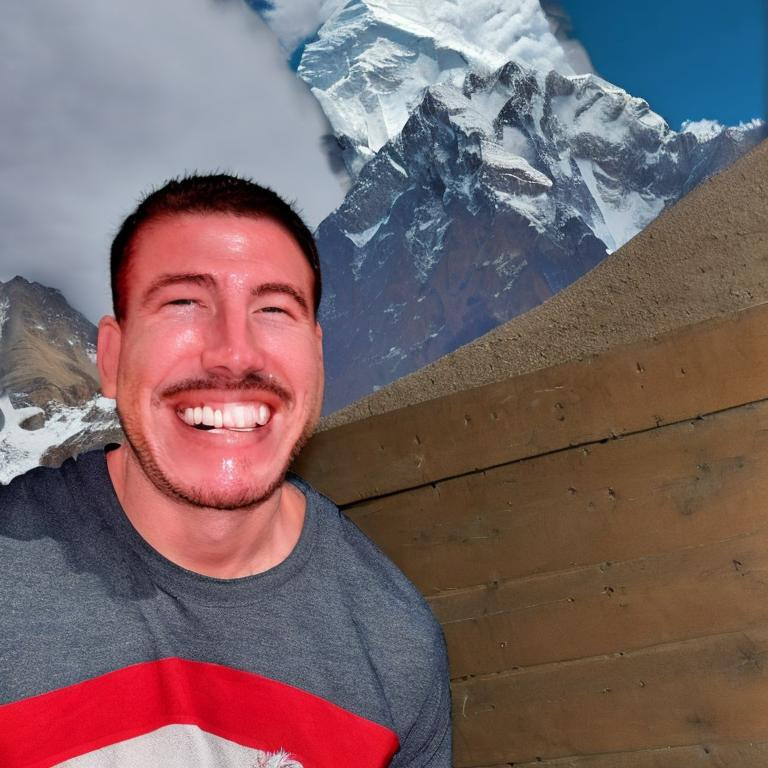
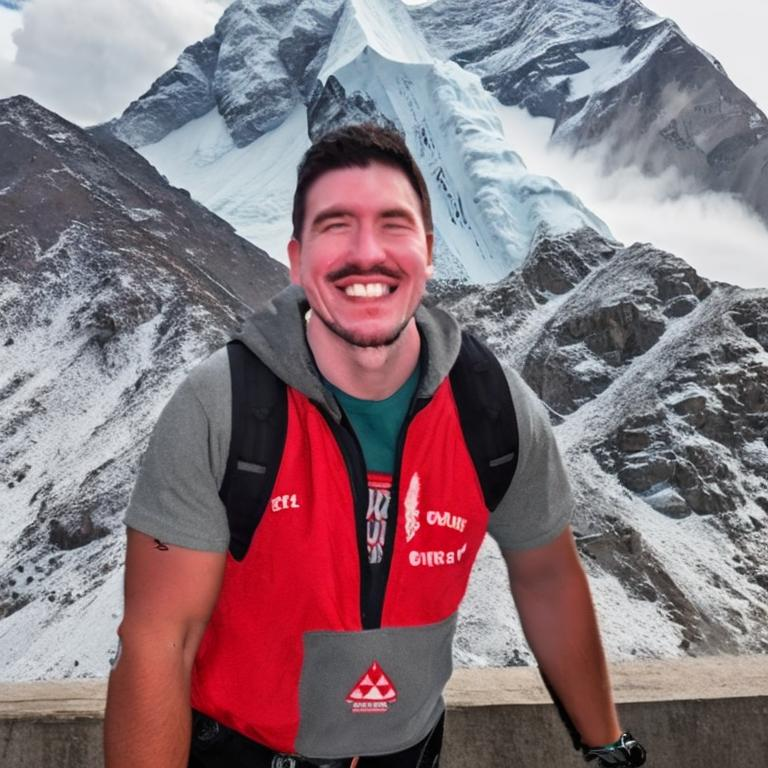
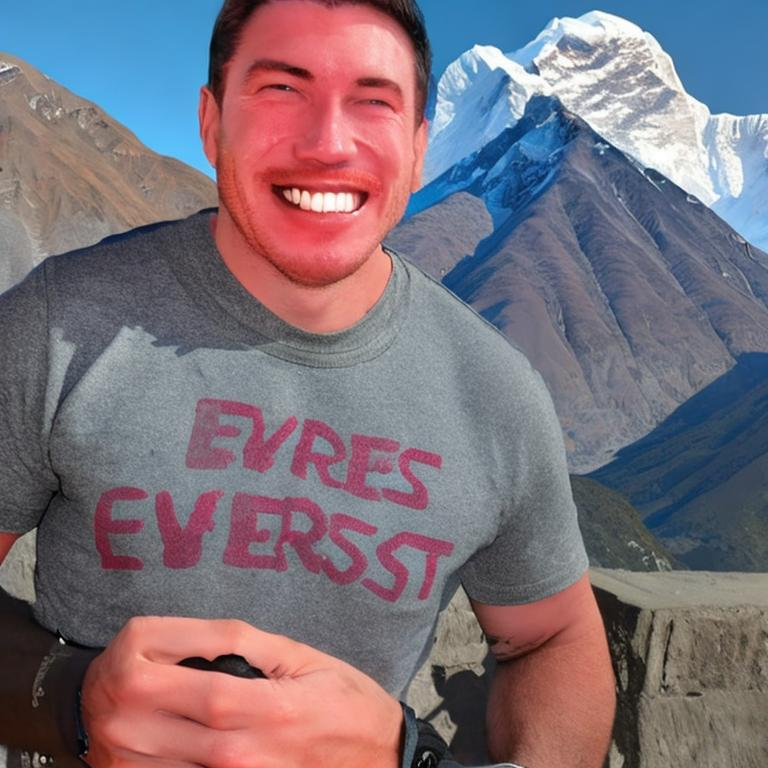
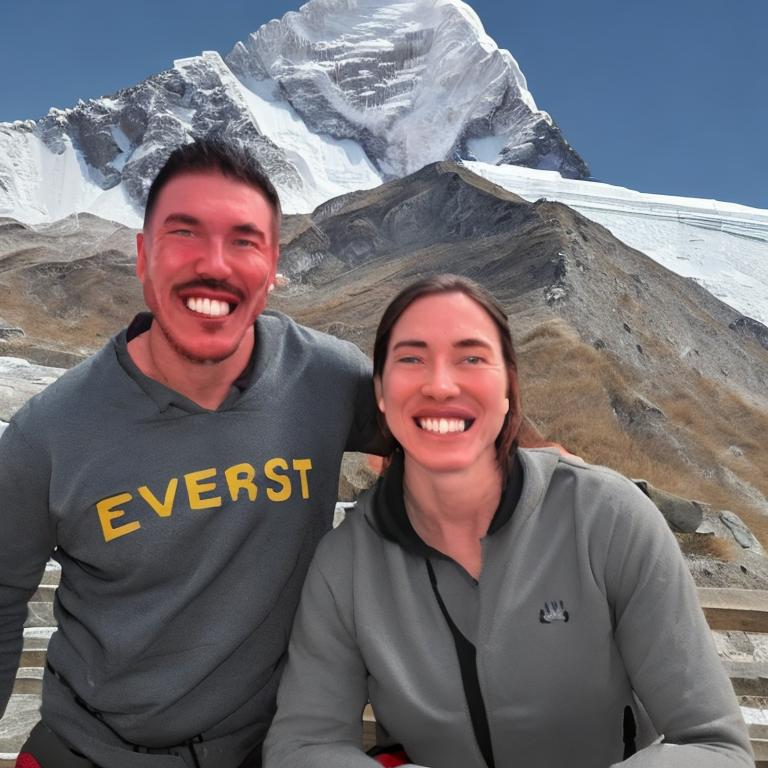
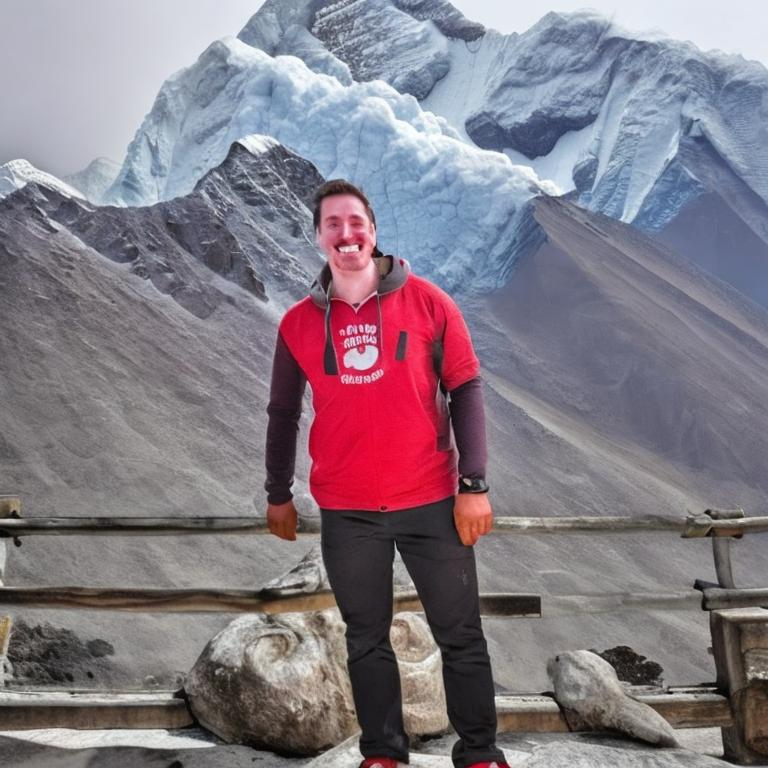

In [ ]:
imgs2test = []
for img in range(0,5):
    image = pipe(PROMPT, num_inference_steps=NUM_INFERENCE_STEPS, guidance_scale=GUIDANCE_SCALE).images[0]
    imgs2test.append(image)

show_img_comparison(imgs2test, resolution=256)

In [ ]:
# @title Instrucciones para generar imágenes (II)
# @markdown `PROMPT` para establecer el prompt que vamos a estar usando.
PROMPT = "A beatiful medieval painting of <mauri> man in a castle with a dragon spitting fire in the background, all inspired in game of thrones." # @param {type:"string"}
# @markdown `NUM_INFERENCE_STEPS` indica la cantidad de denoising steps que vamos a estar tomando.
NUM_INFERENCE_STEPS = 50 # @param {type:"integer"}
# @markdown `GUIDANCE_SCALE` es un número que determina que tanto peso tiene el texto (7-9 es lo común), números bajos dan más libertad al modelo, números altos exigen más fidelidad (12-16).
GUIDANCE_SCALE = 12 # @param {type:"number"}

Generamos 5 imágenes

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

,,,,

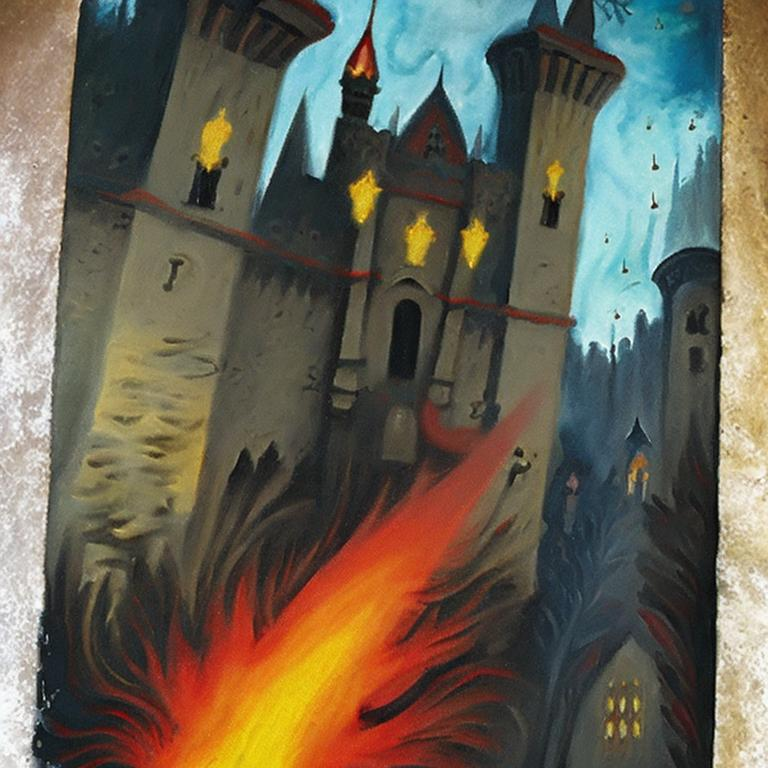
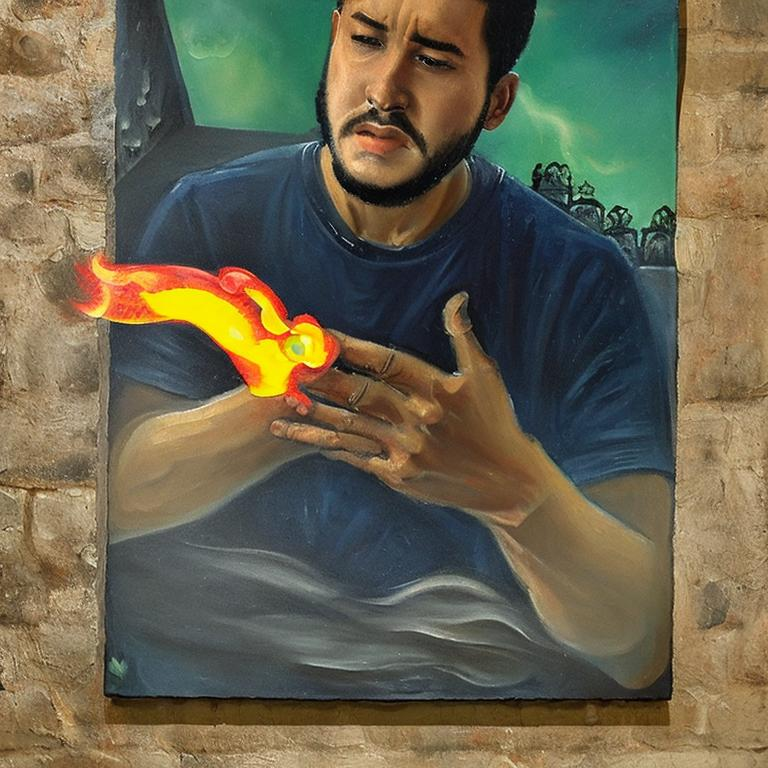
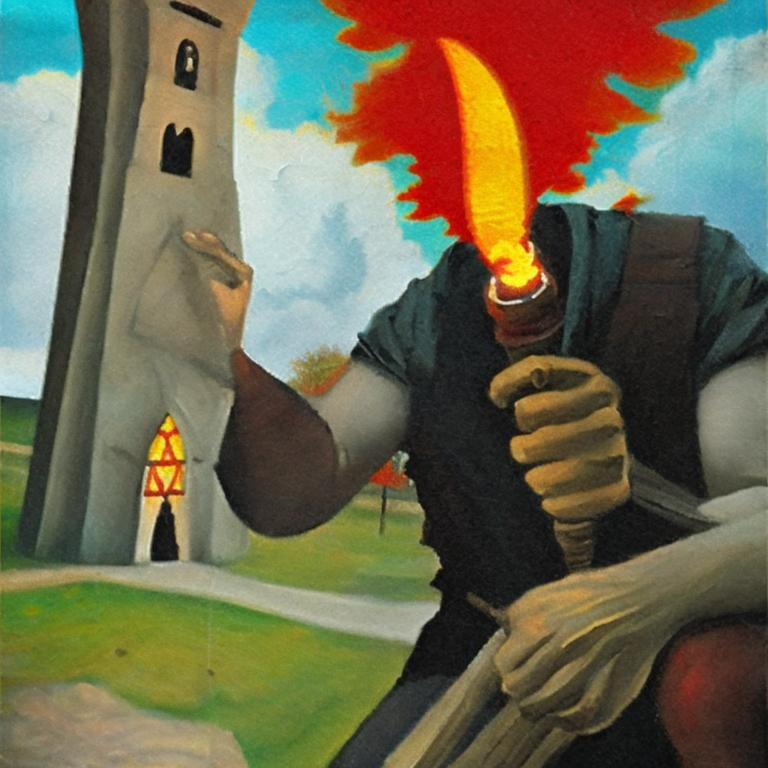
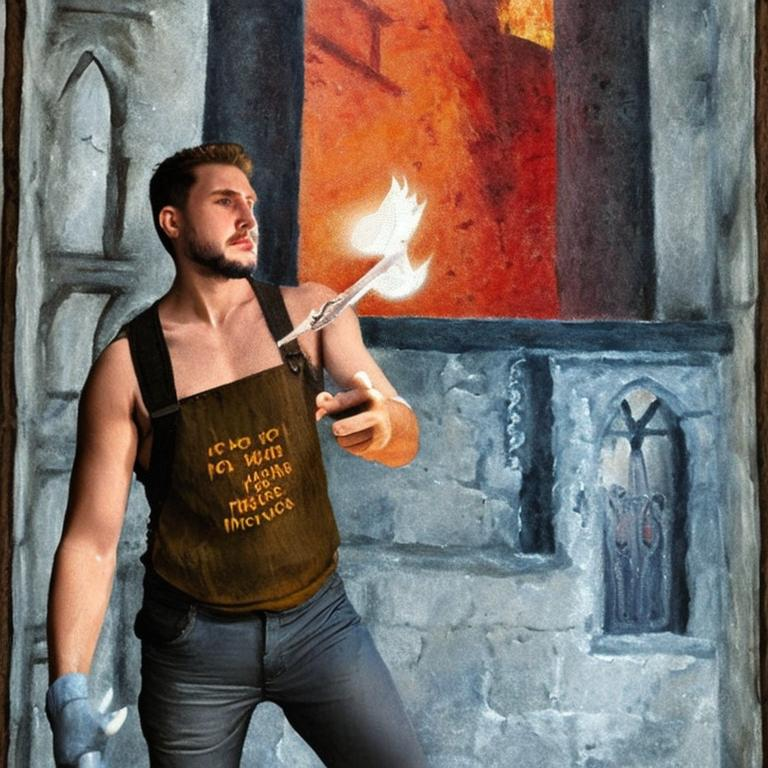
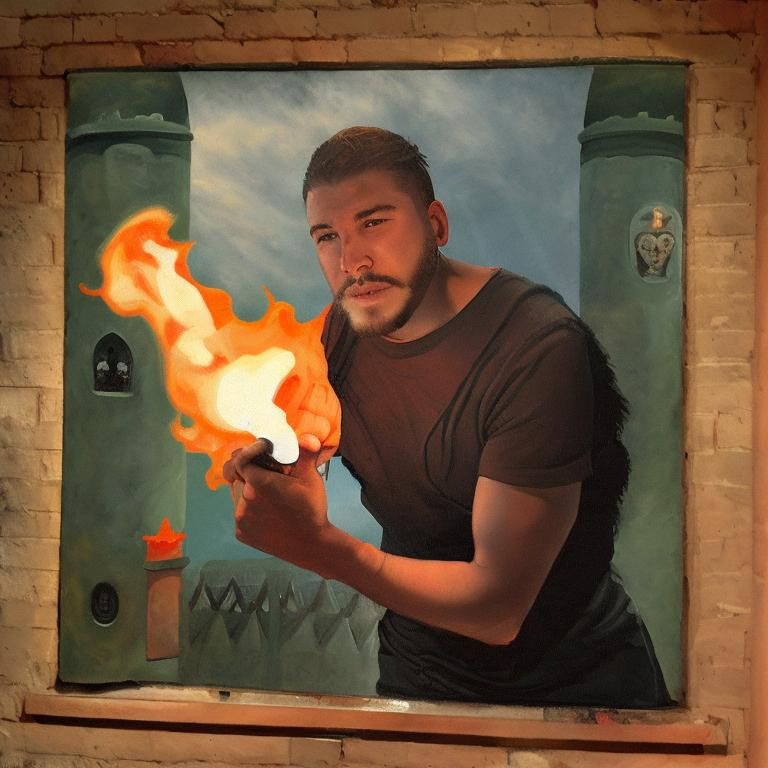

In [ ]:
imgs2test = []
for img in range(0, 5):
    image = pipe(PROMPT, num_inference_steps=NUM_INFERENCE_STEPS, guidance_scale=GUIDANCE_SCALE).images[0]
    imgs2test.append(image)

show_img_comparison(imgs2test, resolution=256)

In [ ]:
# @title Instrucciones para generar imágenes (III)
# @markdown `PROMPT` para establecer el prompt que vamos a estar usando.
PROMPT = "A <mauri> man portrait as a rock star with kiss make-up." # @param {type:"string"}
# @markdown `NUM_INFERENCE_STEPS` indica la cantidad de denoising steps que vamos a estar tomando.
NUM_INFERENCE_STEPS = 50 # @param {type:"integer"}
# @markdown `GUIDANCE_SCALE` es un número que determina que tanto peso tiene el texto (7-9 es lo común), números bajos dan más libertad al modelo, números altos exigen más fidelidad (12-16).
GUIDANCE_SCALE = 12 # @param {type:"number"}

Generamos 5 imágenes

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

,,,,

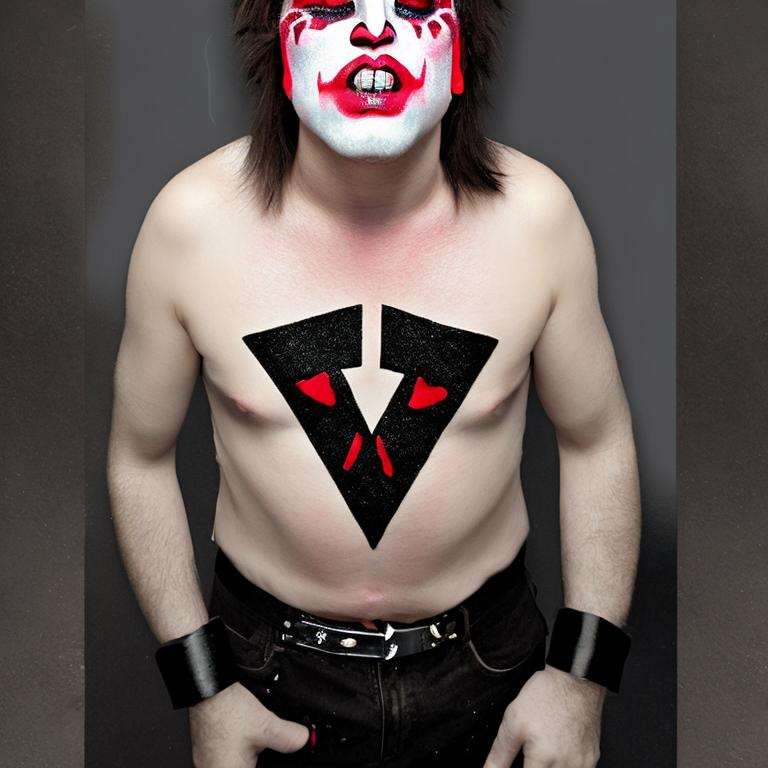
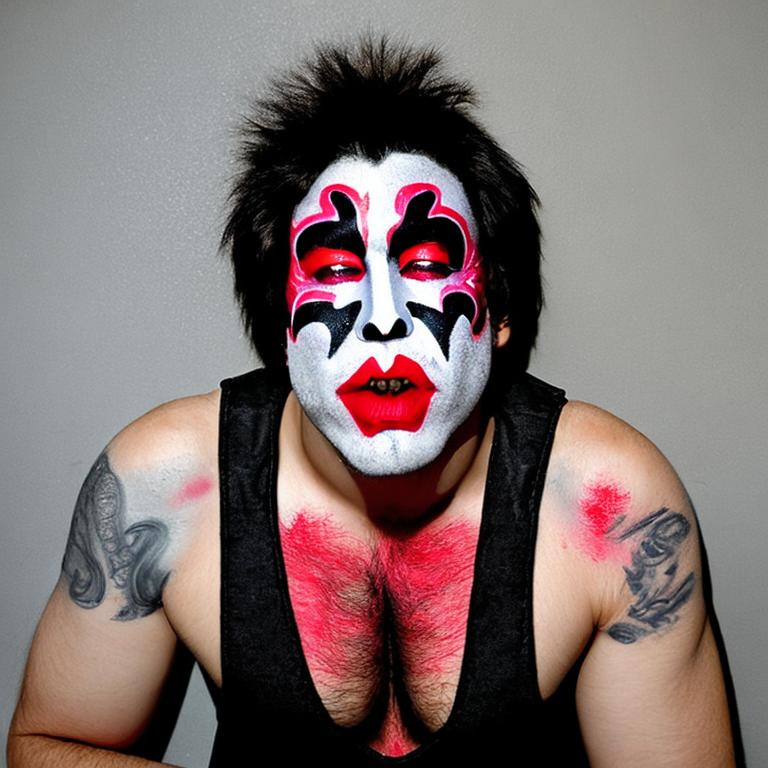
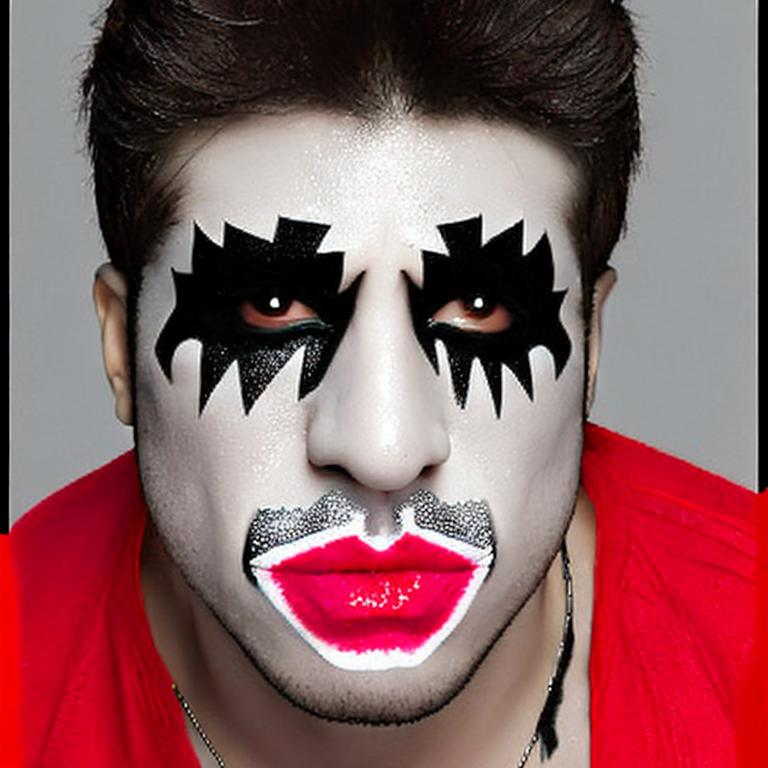
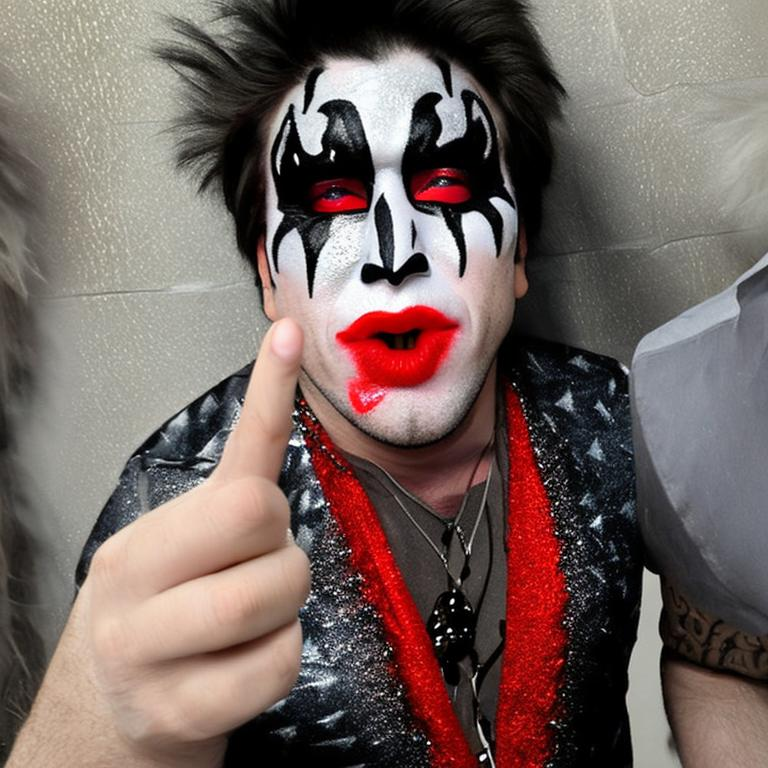
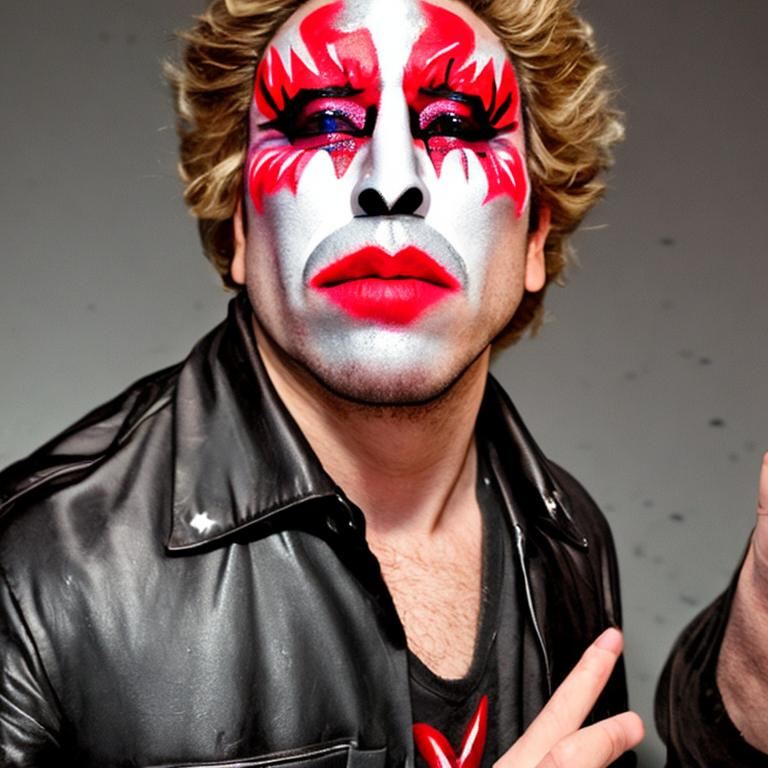

In [ ]:
imgs2test = []
for img in range(0, 5):
    image = pipe(PROMPT, num_inference_steps=NUM_INFERENCE_STEPS, guidance_scale=GUIDANCE_SCALE).images[0]
    imgs2test.append(image)

show_img_comparison(imgs2test, resolution=256)

#### Comparación con SD1.5

"A photo of a smiling \<mauri\> man posing with the Everest mountain in the background"
<table>
<tr>
<td><img src="https://i.imgur.com/oKOxaiw.png" width="250"></td>
<td><img src="https://i.imgur.com/qlV7MMi.png" width="250"></td>
</tr>
</table>

"A beatiful medieval painting of \<mauri\> man in a castle with a dragon spitting fire in the background, all inspired in game of thrones."
<table>
<tr>
<td><img src="https://i.imgur.com/nVzmSCU.png" width="250"></td>
<td><img src="https://i.imgur.com/ZR4YMup.png" width="250"></td>
</tr>
</table>

"A \<mauri\> man portrait as a rock star with kiss make-up."
<table>
<tr>
<td><img src="https://i.imgur.com/yUDSKNy.png" width="250"></td>
<td><img src="https://i.imgur.com/kfgfEbs.png" width="250"></td>
</tr>
</table>

## Con priors

Como habíamos comentado ahora la idea sería, utilizando la misma configuración de parámetros, preservar el conocimiento del modelo y ayudar a que no ocurra principalmente overfitting con respecto a las imágenes.

Vamos ahora a crear nuestra carpeta para almacenar nuestro modelo.

Por defecto está para que se guarde en la VM que nos presta google, pero tener presente que ni bien termine el modelo debemos descargarla a nuestro disco para no perder el contenido, ya que luego de un tiempo la máquina se da de baja y se elimina todo su contenido. O la otra opción es guardarla directamente dentro de nuestro google drive en cualquier carpeta dentro de `/content/drive/MyDrive`.

In [ ]:
# @title Elegir dónde vamos a guardar nuestro modelo
# @markdown `OUTPUTP_DIR` es la ruta donde guardaremos nuestros modelo
OUTPUTP_DIR = "/content/drive/MyDrive/GDG_Medellín/finetuned_models/my_model_dbp_lora" # @param {type:"string"}

if not exists(OUTPUTP_DIR):
    !mkdir -p "$OUTPUTP_DIR"

In [ ]:
# @title Instrucciones para enseñarle un nuevo concepto
# @markdown `INSTANCE_PROMPT`: ¿Qué es lo que le estamos enseñando? Aquí nuetro prompt requiere de usar la clase asociada a nuestro concepto, podríamos usar por ejemplo `man`, `person` o `human`.
INSTANCE_PROMPT = "a photo of a <mauri> man posing for the camera" #@param {type:"string"}
# @markdown `MAX_TRAINING_STEPS` es la cantidad máxima de pasos que vamos a utilizar para finetunear nuestra red. Se recomienda entre 200 y 300 pasos por cada imagen que se tenga para entrenar.
MAX_TRAINING_STEPS = 2100 # @param {type:"integer"}

# Priors
# @markdown ---
# @markdown `CLASS_DIR`: ¿Dónde se van a guardar las imágenes de los priors durante el entrenamiento?
CLASS_DIR = "man" # @param {type:"string"}
# @markdown `CLASS_PROMPT`: Prompt para generar los priors.
CLASS_PROMPT = "a photo of a man" # @param {type:"string"}
# @markdown `NUM_CLASS_IMAGES`: ¿Cuántas imágenes se van a generar para conservar los priors? (normalmente se utilizan 200)
NUM_CLASS_IMAGES = 200 # @param {type:"integer"}

In [ ]:
# @title Selección de nuestro modelo de difusión.
# @markdown `MODEL`: Establecemos nuestro modelo de preferencia, que en este caso será la versión 2-1, si quisieramos usar otras versiones hay que tener presente que la resolución podría necesitar ajustes.
MODEL = "stabilityai/stable-diffusion-2-1" # @param ["Jiali/stable-diffusion-1.5", "runwayml/stable-diffusion-v1-5", "stabilityai/stable-diffusion-2-1"]

Nota: StabilityAI solicitó la baja de runwayml/stable-diffusion-v1-5.

### Training

Ya tenemos todo listo, ahora corramos nuestro script.

En esta ocasión volvemos a hacer uso de ciertos parámetros que nos permitan correr en nuestra modesta GPU:
* gradient checkpointing
* 8-bit optimizer
* xformers
* setear grads a none

Bajo esta configuración de parámetros y con una GPU T4 nuestro script de finetuning debería demorar 3 horas aproximadamente en terminar.

In [ ]:
start_time = datetime.now()
print(f"Starting training at {str(start_time)}")

Starting training at 2024-10-24 19:32:21.453442


In [ ]:
!python3 train_dreambooth_lora.py \
  --pretrained_model_name_or_path="$MODEL" \
  --instance_data_dir="$IMAGES_PATH" \
  --output_dir="$OUTPUTP_DIR" \
  --instance_prompt="$INSTANCE_PROMPT" \
  --resolution=768 \
  --train_batch_size=1 \
  --gradient_accumulation_steps=1 --gradient_checkpointing \
  --use_8bit_adam \
  --enable_xformers_memory_efficient_attention \
  --learning_rate=1e-4 \
  --lr_scheduler="constant" \
  --lr_warmup_steps=0 \
  --max_train_steps=$MAX_TRAINING_STEPS \
  --class_prompt="$CLASS_PROMPT" \
  --class_data_dir="$CLASS_DIR" \
  --with_prior_preservation --prior_loss_weight=1.0 \
  --num_class_images=$NUM_CLASS_IMAGES \
  --seed=1337

2024-10-24 19:32:26.251633: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-24 19:32:26.273357: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-24 19:32:26.279787: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-24 19:32:27.532589: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
10/24/2024 19:32:29 - INFO - __main__ - Distributed environment: NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: no

{'image_encoder'} was not found in config. Values will be initialized to def

In [ ]:
end_time = datetime.now();
print(f"Ending training at {str(end_time)}")

elapsed_time = end_time - start_time

sec = elapsed_time.total_seconds() % (24 * 3600)
hour = sec // 3600
sec %= 3600
min = sec // 60
sec %= 60
print(f">>>>> Total elapsed time: {round(hour)}:{round(min)}:{sec}. <<<<<")

Ending training at 2024-10-24 22:07:50.841029
>>>>> Total elapsed time: 2:35:29.387586999999257. <<<<<


### Inference

Ahora vamos a ver qué tan bien nos conoció la AI. Nuevamente estaremos utilizando un pipeline como ya habíamos explicado en la sección anterior.

In [ ]:
pipe = DiffusionPipeline.from_pretrained(MODEL, safety_checker=None, torch_dtype=torch.float16).to("cuda")
pipe.load_lora_weights(OUTPUTP_DIR)

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/537 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

tokenizer/tokenizer_config.json:   0%|          | 0.00/824 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.36G [00:00<?, ?B/s]

text_encoder/config.json:   0%|          | 0.00/633 [00:00<?, ?B/s]

... (7 outputs left out)

unet/config.json:   0%|          | 0.00/939 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

/usr/local/lib/python3.10/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


In [ ]:
# @title Instrucciones para generar imágenes (I)
# @markdown `PROMPT` para establecer el prompt que vamos a estar usando.
PROMPT = "A photo of a <mauri> man posing with the Everest mountain in the background" # @param {type:"string"}
# @markdown `NUM_INFERENCE_STEPS` indica la cantidad de denoising steps que vamos a estar tomando.
NUM_INFERENCE_STEPS = 50 # @param {type:"integer"}
# @markdown `GUIDANCE_SCALE` es un número que determina que tanto peso tiene el texto (7-9 es lo común), números bajos dan más libertad al modelo, números altos exigen más fidelidad (12-16).
GUIDANCE_SCALE = 12 # @param {type:"number"}

Generamos 4 imágenes

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

,,,,

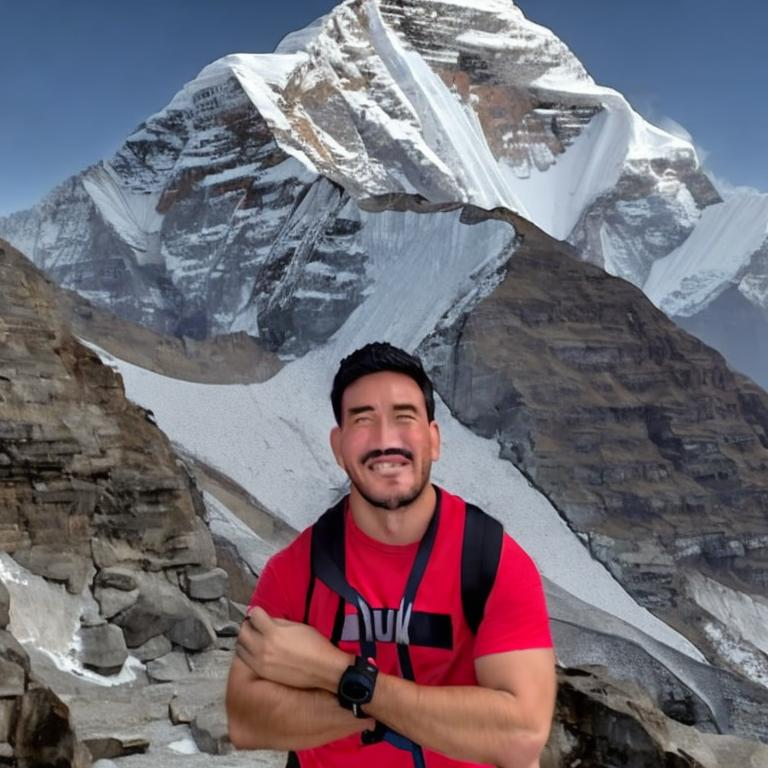
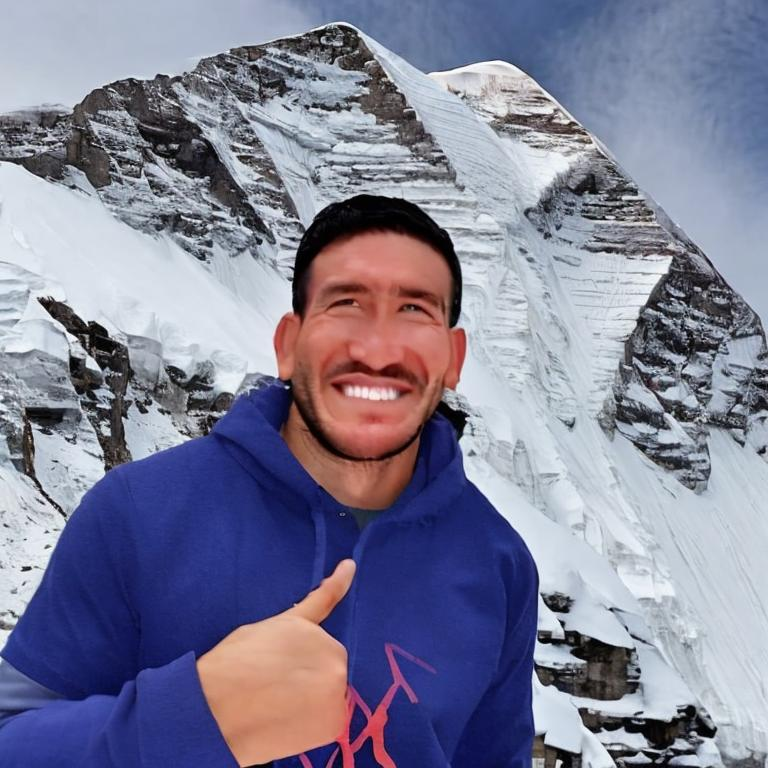
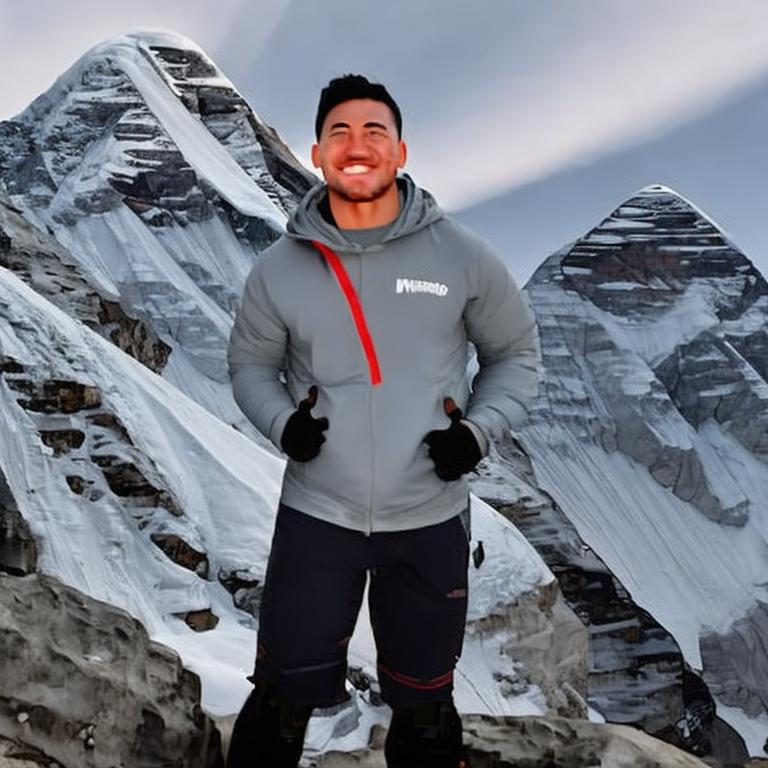
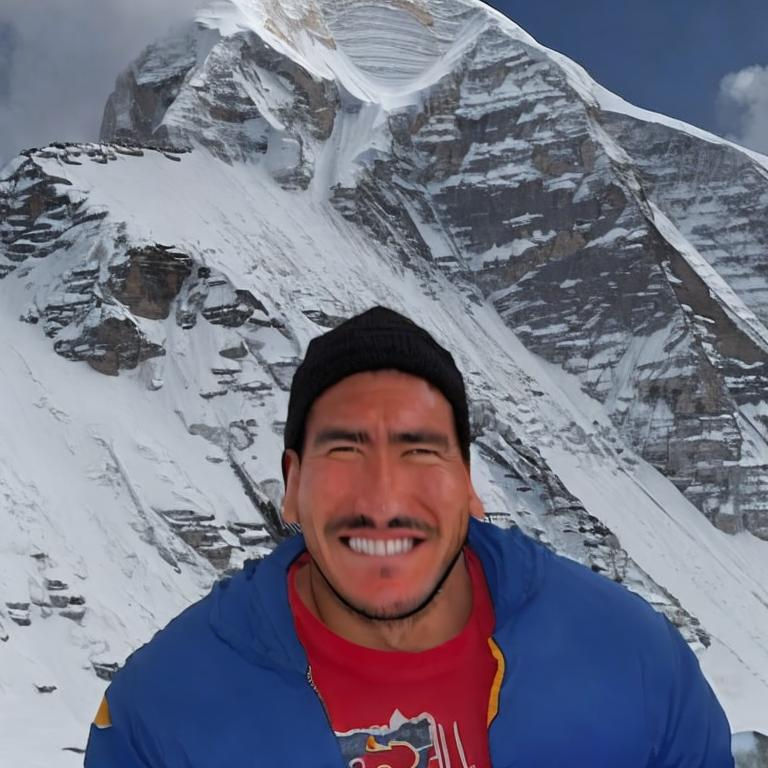
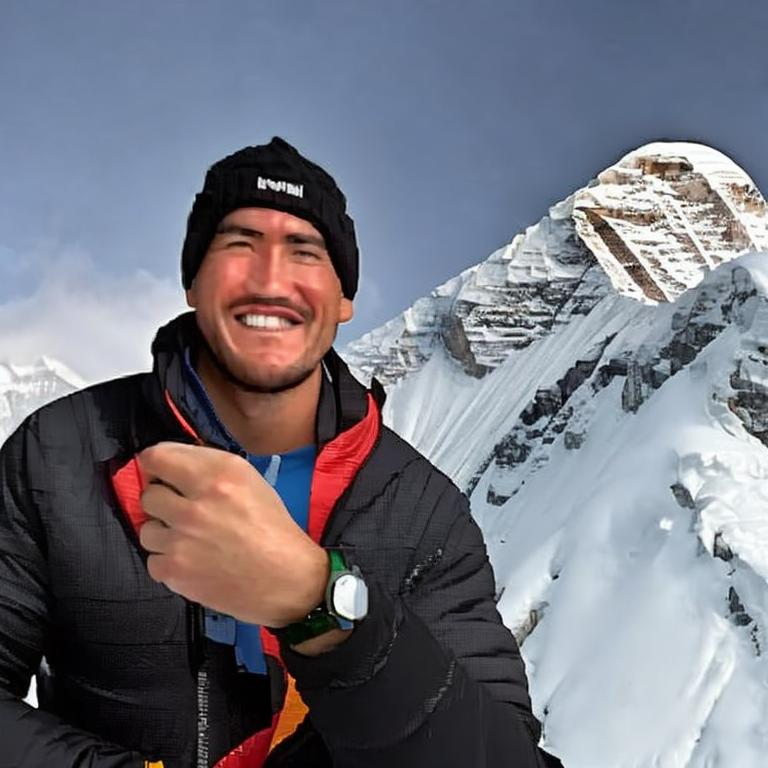

In [ ]:
imgs2test = []
for img in range(0, 5):
    image = pipe(PROMPT, num_inference_steps=NUM_INFERENCE_STEPS, guidance_scale=GUIDANCE_SCALE).images[0]
    imgs2test.append(image)

show_img_comparison(imgs2test, resolution=256)

In [ ]:
# @title Instrucciones para generar imágenes (II)
# @markdown `PROMPT` para establecer el prompt que vamos a estar usando.
PROMPT = "A beatiful medieval painting of <mauri> man in a castle with a dragon spitting fire in the background, all inspired in game of thrones." # @param {type:"string"}
# @markdown `NUM_INFERENCE_STEPS` indica la cantidad de denoising steps que vamos a estar tomando.
NUM_INFERENCE_STEPS = 50 # @param {type:"integer"}
# @markdown `GUIDANCE_SCALE` es un número que determina que tanto peso tiene el texto (7-9 es lo común), números bajos dan más libertad al modelo, números altos exigen más fidelidad (12-16).
GUIDANCE_SCALE = 12 # @param {type:"number"}

Generamos 5 imágenes

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

,,,,

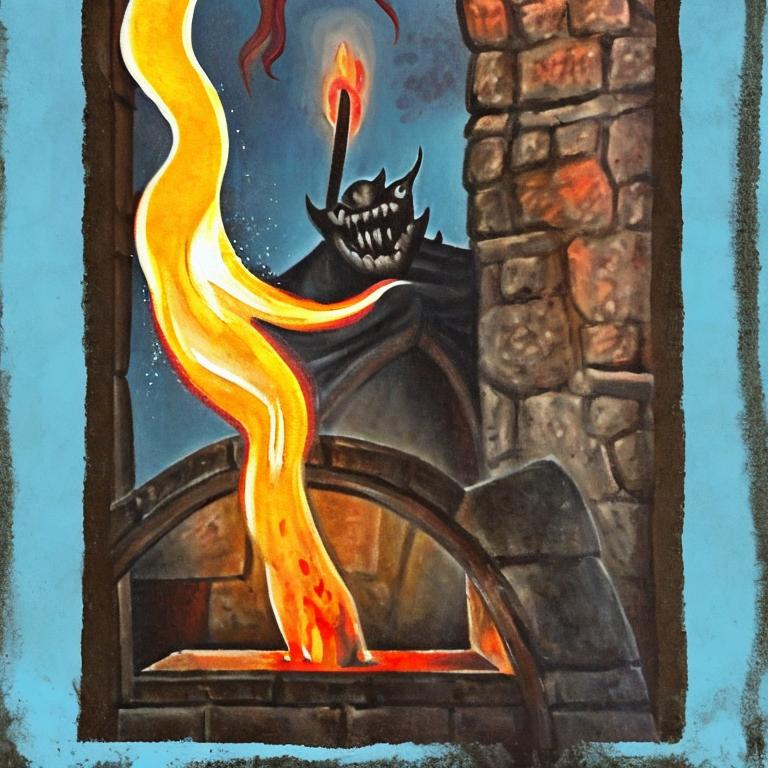
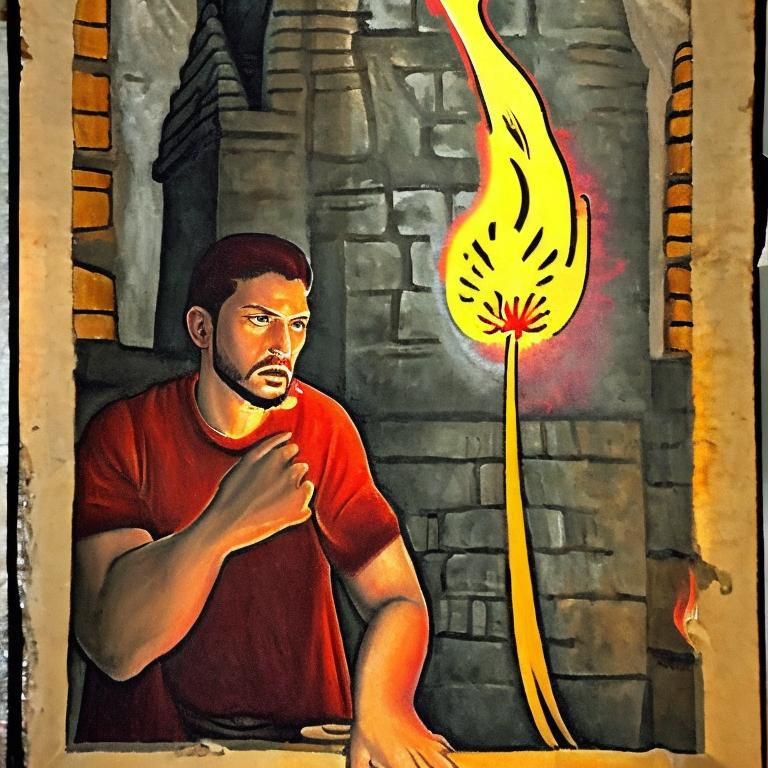
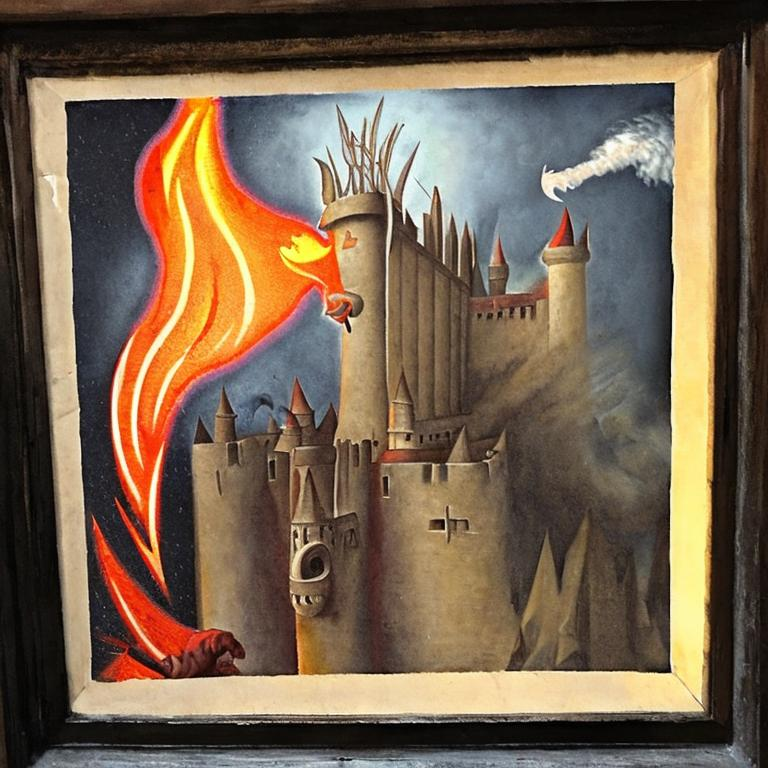
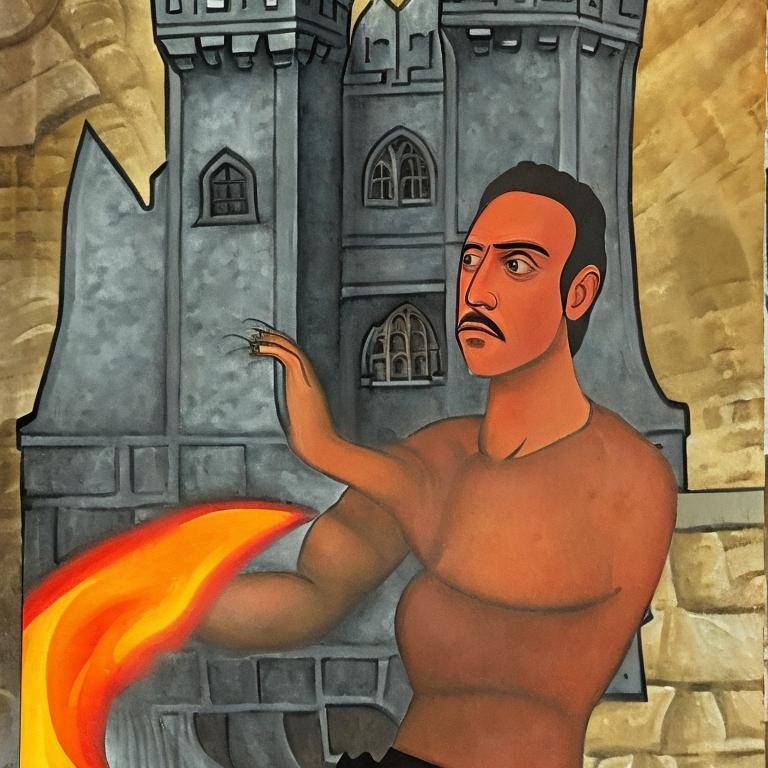
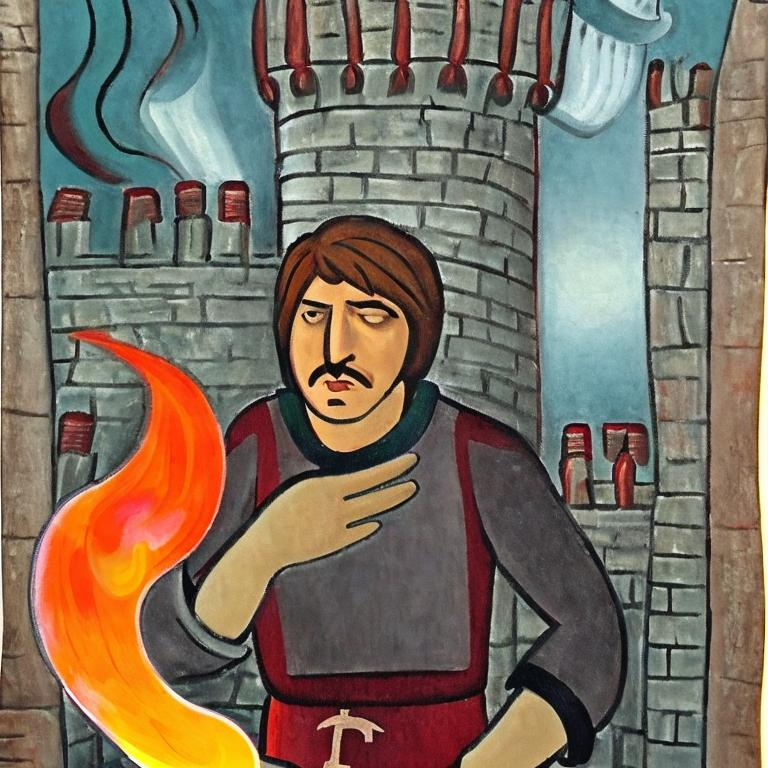

In [ ]:
imgs2test = []
for img in range(0, 5):
    image = pipe(PROMPT, num_inference_steps=NUM_INFERENCE_STEPS, guidance_scale=GUIDANCE_SCALE).images[0]
    imgs2test.append(image)

show_img_comparison(imgs2test, resolution=256)

In [ ]:
# @title Instrucciones para generar imágenes (III)
# @markdown `PROMPT` para establecer el prompt que vamos a estar usando.
PROMPT = "A <mauri> man portrait as a rock star with kiss make-up." # @param {type:"string"}
# @markdown `NUM_INFERENCE_STEPS` indica la cantidad de denoising steps que vamos a estar tomando.
NUM_INFERENCE_STEPS = 50 # @param {type:"integer"}
# @markdown `GUIDANCE_SCALE` es un número que determina que tanto peso tiene el texto (7-9 es lo común), números bajos dan más libertad al modelo, números altos exigen más fidelidad (12-16).
GUIDANCE_SCALE = 12 # @param {type:"number"}

Generamos 5 imágenes

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

,,,,

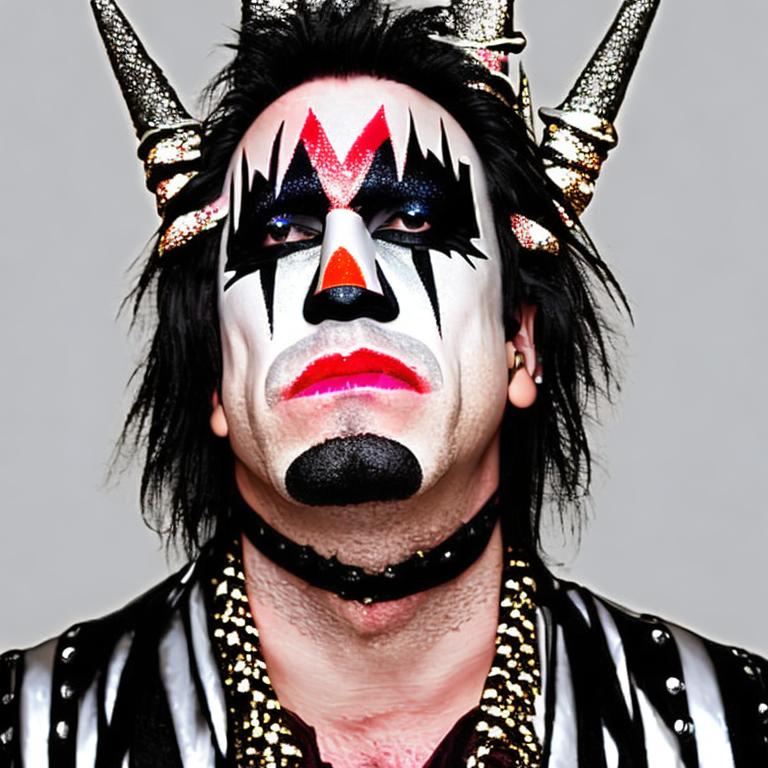
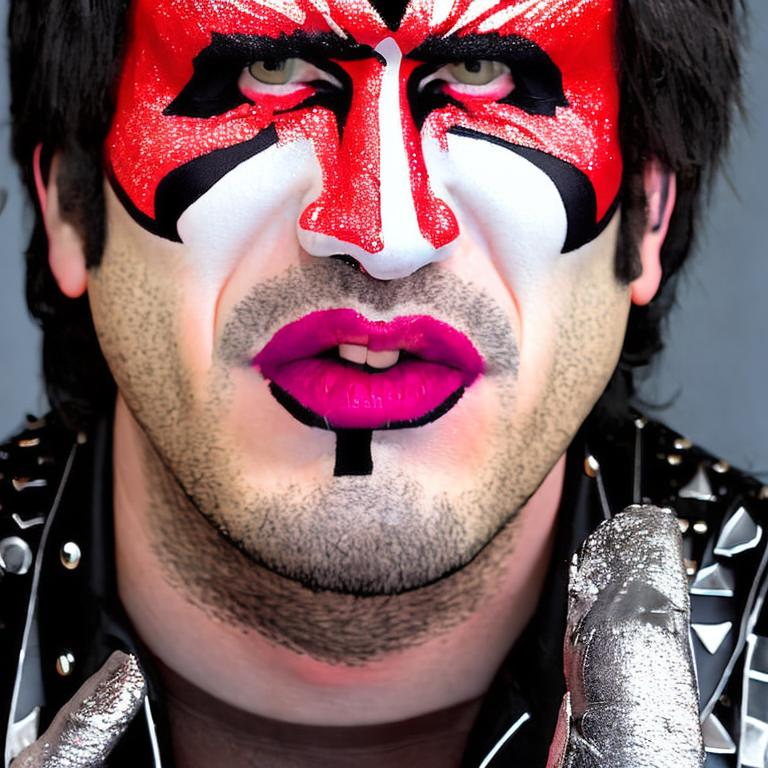
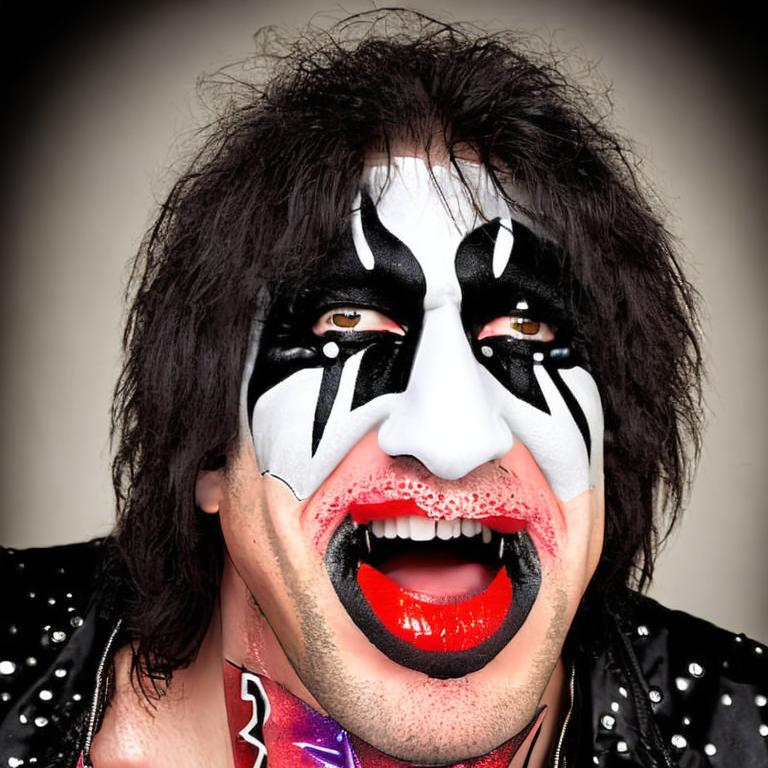
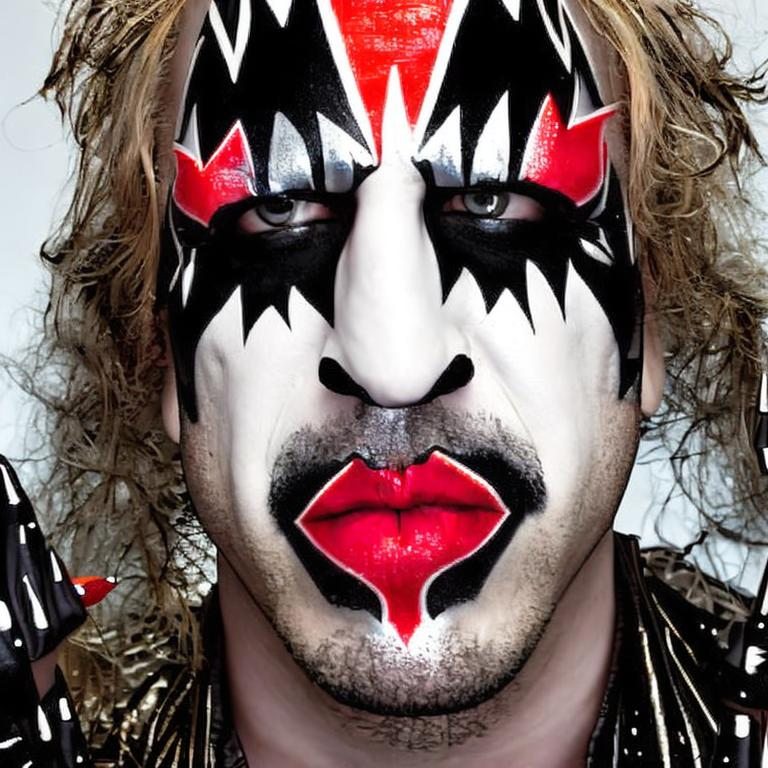
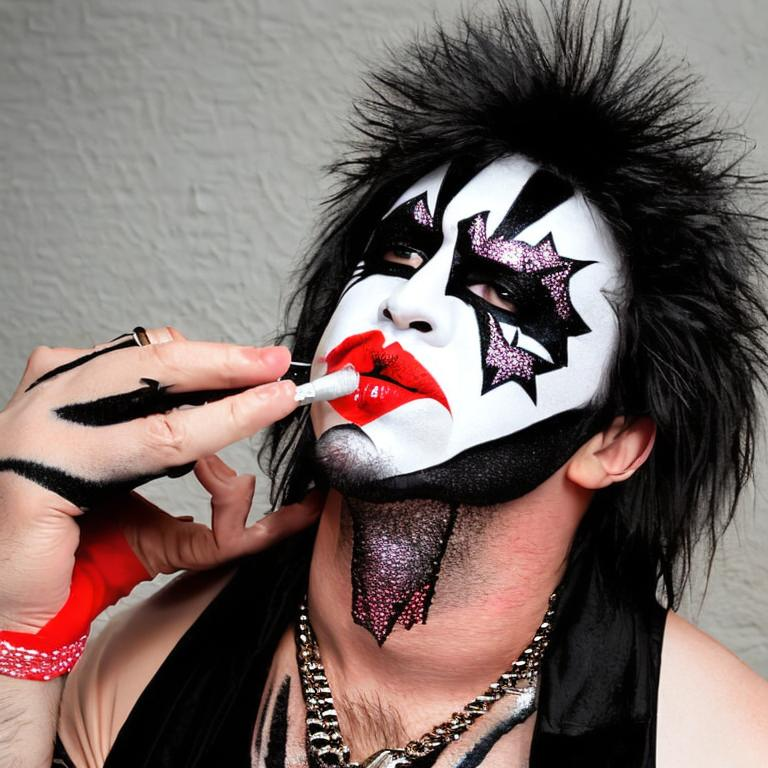

In [ ]:
imgs2test = []
for img in range(0, 5):
    image = pipe(PROMPT, num_inference_steps=NUM_INFERENCE_STEPS, guidance_scale=GUIDANCE_SCALE).images[0]
    imgs2test.append(image)

show_img_comparison(imgs2test, resolution=256)

#### Comparación con SD1.5

"A photo of a smiling \<mauri\> man posing with the Everest mountain in the background"
<table>
<tr>
<td><img src="https://i.imgur.com/dhUhSZ5.png" width="250"></td>
<td><img src="https://i.imgur.com/q0IRjZ8.png" width="250"></td>
</tr>
</table>

"A beatiful medieval painting of \<mauri\> man in a castle with a dragon spitting fire in the background, all inspired in game of thrones."
<table>
<tr>
<td><img src="https://i.imgur.com/dDRgwaF.png" width="250"></td>
<td><img src="https://i.imgur.com/6o9pVEh.png" width="250"></td>
</tr>
</table>

"A \<mauri\> man portrait as a rock star with kiss make-up."
<table>
<tr>
<td><img src="https://i.imgur.com/JnybxNy.png" width="250"></td>
<td><img src="https://i.imgur.com/SZ7wv5T.png" width="250"></td>
</tr>
</table>

Eventualmente si desean usar éstos modelos de forma más interactiva podrían probar con una [WebUI](https://github.com/AUTOMATIC1111/stable-diffusion-webui) de Automatic1111 que resulta fácil y divertido de utilizar. Hay también notebooks disponibles para levantar dicha interfaz desde el navegador [aquí](https://github.com/AUTOMATIC1111/stable-diffusion-webui/wiki/Online-Services).